# Welcome, analyst! 🐧

In this notebook, you're the analyst. You ask the questions, judge the answers, and make the claims. The AI assistant helps with the code, but the conclusions are yours. Take your time, stay curious, and question everything, including the assistant.

# 01 · First look: Palmer penguins

You explore data by asking questions. The AI assistant writes the code, in this notebook, and **you** run it, check it, and decide what it means.

**How to ask:** click the chat icon (two speech bubbles) in the left sidebar, then **New chat**. In the menu at the bottom left of the chat, pick **Claude** (or keep **Jupyternaut**, Jupyter AI's own assistant). Keep this notebook open, and ask for cells: *"Add cells to my notebook that show which island has the most penguins."* It asks your permission before it changes the notebook.

**Quick questions in a cell:** start a cell with `%%ai` and write your question below it. The answer appears under the cell.

Every question goes through six steps: **Question → Plan → Compute → Check → Claim → Review**.

### Before you believe a result
1. **Read the sentence** above the code. Is that what you asked?
2. **Read the code.** Does it do what the sentence says? Ask the assistant about any line you can't follow.
3. **Run Compute, then Check.** Do they agree?
4. **Compare with what the assistant said to expect.** Surprised? Find out why before going on.
5. **Look at a few raw rows** behind the result.

Only then write your **Claim** and ask the assistant to review it.

## The data

Measurements of 344 penguins on three islands in Antarctica, 2007–2009 (Palmer Station LTER, via the `palmerpenguins` package, CC0). Run the next two cells: the first loads the data, the second shows what's in it.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

penguins = pd.read_csv("../data/penguins.csv")
penguins.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


How many rows and columns, what type each column is, and how many values are missing in each:

In [2]:
print(penguins.shape)
penguins.info()

(344, 8)
<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), str(3)
memory usage: 21.6 KB


---
## Worked example

This is what one question looks like when it's done. Read it top to bottom, and run the cells.

**Question.** Which species is heaviest on average? We use `body_mass_g` (grams) and compare the mean for each `species`, leaving out penguins with no recorded mass.

**Plan.** Group the penguins by species and take the mean body mass of each group. Pandas skips missing values when taking a mean, so penguins with no mass are left out. Expect three numbers, each a few thousand grams.

**Compute:** the mean body mass in grams for each species, ignoring missing values.

In [3]:
penguins.groupby("species")["body_mass_g"].mean().sort_values()

species
Adelie       3700.662252
Chinstrap    3733.088235
Gentoo       5076.016260
Name: body_mass_g, dtype: float64

**Check:** for each species, add up the masses by hand and divide by how many penguins have a mass. This should match the numbers above. It also shows how many penguins each average is based on.

In [4]:
for sp in ["Adelie", "Chinstrap", "Gentoo"]:
    masses = penguins.loc[penguins["species"] == sp, "body_mass_g"].dropna()
    print(sp, len(masses), "penguins, mean", round(masses.sum() / len(masses), 1))

Adelie 151 penguins, mean 3700.7
Chinstrap 68 penguins, mean 3733.1
Gentoo 123 penguins, mean 5076.0


**Claim:** Among the 342 penguins with a recorded body mass, Gentoo penguins are the heaviest on average, at about 5,076 g, compared with about 3,700 g for Adelie and Chinstrap.

**Review:** *(ask the assistant: "Review the claim in my notebook. Do the numbers match the outputs, and does it say more than the data shows?")*

---
## Your turn

Ask the assistant a question about the penguins. Some ideas:
- Which island has the most penguins, and which species live there?
- Do male and female penguins differ in bill length?
- Is flipper length related to body mass? Show me.

---
## Five things in the penguin data

The assistant noticed five things in the data. Each one is set out below as a question, using the same steps as the worked example. The assistant wrote the Question, Plan, Compute and Check cells. Run them, compare the outputs, and then write each **Claim** yourself.

### 1 · Which species live on which island?

**Question.** How many penguins of each `species` were recorded on each `island`? Are any species found on only one island?

**Plan.** Make a table with one row per species and one column per island, and count the penguins in each box. Every penguin has a species and an island, so all 344 should be counted. A 0 means no penguins of that species were recorded on that island. It doesn't prove there are none there.

**Compute:** count the penguins of each species on each island.

In [5]:
pd.crosstab(penguins["species"], penguins["island"])

island,Biscoe,Dream,Torgersen
species,,,
Adelie,44,56,52
Chinstrap,0,68,0
Gentoo,124,0,0


**Check:** count again a different way, by grouping on island and species, and make sure the counts add up to all 344 penguins. Only combinations that actually occur are listed, so the missing ones should be the 0s in the table above.

In [6]:
counts = penguins.groupby(["island", "species"]).size()
print(counts.sum(), "penguins counted, out of", len(penguins))
counts

344 penguins counted, out of 344


island     species  
Biscoe     Adelie        44
           Gentoo       124
Dream      Adelie        56
           Chinstrap     68
Torgersen  Adelie        52
dtype: int64

**Claim:** 

### 2 · How do the species differ in size?

**Question.** For each `species`, what are the average `bill_length_mm`, `bill_depth_mm`, `flipper_length_mm` (all in millimetres) and `body_mass_g` (grams)? "Average" here means the mean.

**Plan.** Group the penguins by species and take the mean of each of the four measurements. Two penguins have no measurements at all, and pandas leaves them out of the means. The worked example already covered body mass, so the new parts here are the bill and flipper columns.

**Compute:** the mean of each measurement for each species, rounded to one decimal place.

In [7]:
measurements = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
penguins.groupby("species")[measurements].mean().round(1)

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
species,,,,
Adelie,38.8,18.3,190.0,3700.7
Chinstrap,48.8,18.4,195.8,3733.1
Gentoo,47.5,15.0,217.2,5076.0


**Check:** take just the Gentoo rows and work out each mean by hand: the sum divided by how many values there are. These should match the Gentoo row above.

In [8]:
gentoo = penguins[penguins["species"] == "Gentoo"]
print(len(gentoo), "Gentoo rows")
(gentoo[measurements].sum() / gentoo[measurements].count()).round(1)

124 Gentoo rows


bill_length_mm         47.5
bill_depth_mm          15.0
flipper_length_mm     217.2
body_mass_g          5076.0
dtype: float64

**Claim:** 

### 3 · Are males heavier than females in every species?

**Question.** Within each `species`, is the mean `body_mass_g` of males higher than that of females, and by how many grams?

**Plan.** Group by species *and* sex, take the mean mass of each group, and put males and females side by side. 11 penguins have no recorded `sex`. Grouping leaves them out automatically, so this compares only penguins whose sex is known.

**Compute:** the mean body mass in grams for each species and sex, with females and males in separate columns.

In [9]:
penguins.groupby(["species", "sex"])["body_mass_g"].mean().round().unstack()

sex,female,male
species,,
Adelie,3369.0,4043.0
Chinstrap,3527.0,3939.0
Gentoo,4680.0,5485.0


**Check:** for each species, pick out the males and the females separately, count them, and subtract the female mean from the male mean. The differences should match the gaps in the table above, and the counts show how many penguins each mean is based on.

In [10]:
for sp in ["Adelie", "Chinstrap", "Gentoo"]:
    rows = penguins[penguins["species"] == sp]
    male = rows.loc[rows["sex"] == "male", "body_mass_g"]
    female = rows.loc[rows["sex"] == "female", "body_mass_g"]
    print(sp, ":", male.count(), "males,", female.count(), "females, males heavier by", round(male.mean() - female.mean()), "g")

Adelie : 73 males, 73 females, males heavier by 675 g
Chinstrap : 34 males, 34 females, males heavier by 412 g
Gentoo : 61 males, 58 females, males heavier by 805 g


**Claim:** 

### 4 · Do penguins with longer flippers weigh more?

**Question.** Across all penguins, how closely does `flipper_length_mm` go with `body_mass_g`? We measure "how closely" with the **correlation**, a number from −1 to 1. 1 means the points lie exactly on a rising line, 0 means no straight-line pattern, and −1 means they lie exactly on a falling line.

**Plan.** Compute the correlation between the two columns. Pandas skips the 2 penguins with no measurements. A single number can hide a lot (curves, clusters, odd points), so the check is to look at every penguin on a scatter plot.

**Compute:** the correlation between flipper length and body mass, rounded to two decimal places.

In [11]:
round(penguins["flipper_length_mm"].corr(penguins["body_mass_g"]), 2)

np.float64(0.87)

**Check:** plot every penguin, one dot each. If the number above is close to 1, the dots should form a narrow band rising from bottom left to top right. If they don't, trust the picture and ask why.

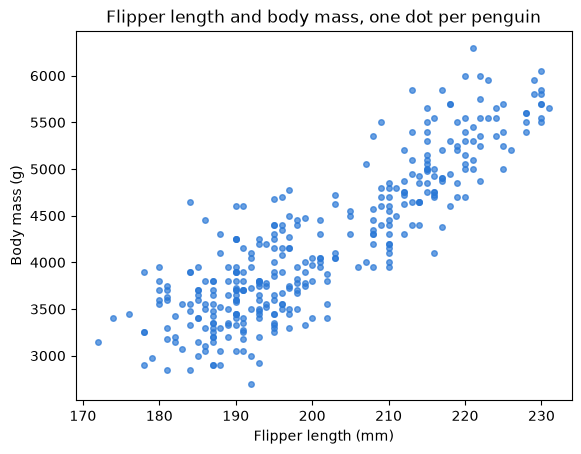

In [12]:
fig, ax = plt.subplots()
ax.scatter(penguins["flipper_length_mm"], penguins["body_mass_g"], s=16, color="#2a78d6", alpha=0.7)
ax.set_title("Flipper length and body mass, one dot per penguin")
ax.set_xlabel("Flipper length (mm)")
ax.set_ylabel("Body mass (g)")
plt.show()

**Claim:** 

### 5 · Do longer bills come with deeper bills?

**Question.** What is the correlation between `bill_length_mm` and `bill_depth_mm`, first across all penguins and then within each `species` separately? Do the two answers agree?

**Plan.** Compute one correlation for all penguins together, then one for each species on its own rows. The 2 penguins with no measurements are skipped. If the overall answer and the per-species answers point in different directions, a scatter plot colored by species should show why.

**Compute:** the correlation between bill length and bill depth for all penguins, then for each species.

In [13]:
print("All penguins:", round(penguins["bill_length_mm"].corr(penguins["bill_depth_mm"]), 2))
for sp in ["Adelie", "Chinstrap", "Gentoo"]:
    rows = penguins[penguins["species"] == sp]
    print(sp + ":", round(rows["bill_length_mm"].corr(rows["bill_depth_mm"]), 2))

All penguins: -0.24
Adelie: 0.39
Chinstrap: 0.65
Gentoo: 0.64


**Check:** plot every penguin, with a different color and shape for each species. Look at each species' cloud on its own: which way does it slope? Then look at all the dots together: which way does the whole picture slope? Both should agree with the numbers above.

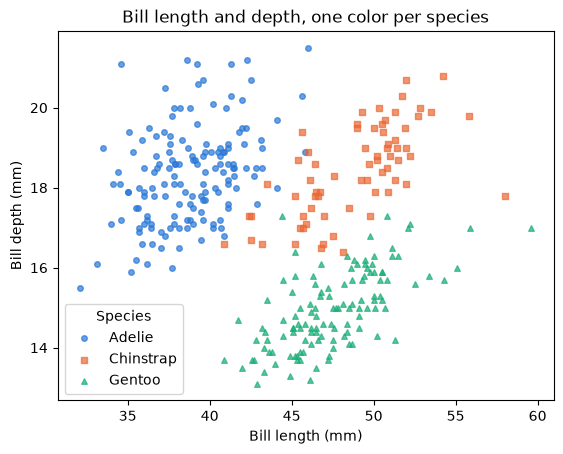

In [14]:
colors = {"Adelie": "#2a78d6", "Chinstrap": "#eb6834", "Gentoo": "#1baf7a"}
markers = {"Adelie": "o", "Chinstrap": "s", "Gentoo": "^"}

fig, ax = plt.subplots()
for sp in ["Adelie", "Chinstrap", "Gentoo"]:
    rows = penguins[penguins["species"] == sp]
    ax.scatter(rows["bill_length_mm"], rows["bill_depth_mm"], s=16, color=colors[sp], marker=markers[sp], alpha=0.7, label=sp)
ax.set_title("Bill length and depth, one color per species")
ax.set_xlabel("Bill length (mm)")
ax.set_ylabel("Bill depth (mm)")
ax.legend(title="Species")
plt.show()

In [18]:
%%ai 

when we asked about one species being bigger than another, should we divide by gender?


**Often, yes.** Separating by sex matters most when the species show **sexual size dimorphism**, meaning males and females differ noticeably in size. (In biology the usual term is **sex**, not gender, since it refers to biological traits.)

## Why it matters

1. **The answer can flip depending on which sex you compare.**
   - Gorillas: males are about twice the mass of females.
   - Elephant seals: males can be 3 to 7 times heavier than females.
   - Many spiders, birds of prey, and anglerfish: females are larger, sometimes dramatically.

   If species A has huge males and small females, and species B has little dimorphism, "Is A bigger than B?" might be true for males but false for females.

2. **Pooled averages can be misleading.** If your sample has more males of one species and more females of the other, a combined average reflects your sampling, not a real species difference.

3. **Variance increases.** Mixing sexes widens the spread of the data, which can hide real differences or make statistical tests less powerful.

## When you might not need to separate

- The species show little or no size dimorphism (many monomorphic birds, some fish).
- The size difference between species dwarfs the difference between sexes, such as comparing a mouse to a horse.
- You can't sex the individuals reliably (some birds, fossils, juveniles). In that case, acknowledge it as a limitation.

## Good practice

- **Report male and female data separately**, or at least check whether the sexes differ before pooling.
- **Use sex as a factor in your analysis.** For example, a two-way ANOVA or linear model with *species*, *sex*, and *species × sex* interaction. A significant interaction means the size difference between species depends on sex.
- **If pooling, balance your samples** so both species have similar male:female ratios.
- **Control for other confounders too:** age (adults only), population or geographic region, season (body mass fluctuates), and which measure of "size" you use (mass, length, wing span, etc.).

**Bottom line:** Compare like with like. Unless you know the sexes are similar in size, analyze them separately or include sex in your model.

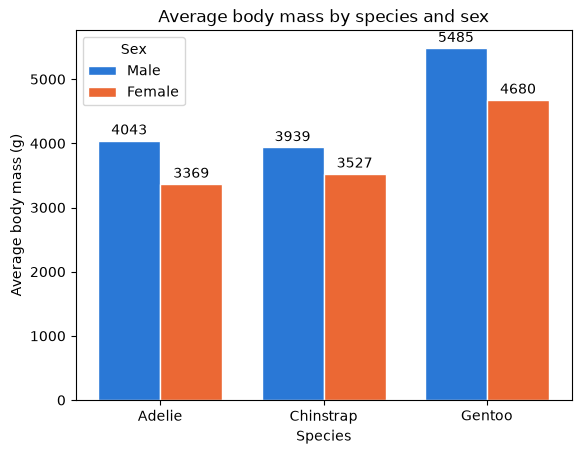

In [19]:
# The data has no height column, so this uses body mass
means = penguins.groupby(["species", "sex"])["body_mass_g"].mean().unstack()
x = range(len(means.index))
width = 0.38

fig, ax = plt.subplots()
male = ax.bar([i - width / 2 for i in x], means["male"], width, color="#2a78d6", label="Male", edgecolor="white")
female = ax.bar([i + width / 2 for i in x], means["female"], width, color="#eb6834", label="Female", edgecolor="white")
ax.bar_label(male, fmt="%.0f", padding=2)
ax.bar_label(female, fmt="%.0f", padding=2)
ax.set_xticks(list(x), means.index)
ax.set_title("Average body mass by species and sex")
ax.set_xlabel("Species")
ax.set_ylabel("Average body mass (g)")
ax.legend(title="Sex")
plt.show()

**Comment on the plot.** In all three species, males are heavier than females on average:

| Species | Males | Females | Males heavier by |
|---|---|---|---|
| Adelie | 4,043 g (73 penguins) | 3,369 g (73) | 675 g, about 20% |
| Chinstrap | 3,939 g (34) | 3,527 g (34) | 412 g, about 12% |
| Gentoo | 5,485 g (61) | 4,680 g (58) | 805 g, about 17% |

- **The gap varies.** Gentoos have the largest gap in grams, Adelies the largest relative to their size, and Chinstraps the smallest by both measures.
- **Species matters more than sex.** Gentoo *females* are heavier on average than Adelie or Chinstrap *males*.
- **Chinstraps and Adelies.** The two species were almost the same overall (about 3,700 g each), but Chinstrap females are about 160 g heavier than Adelie females, while Adelie males are about 100 g heavier than Chinstrap males.

These are averages. They don't show how much individual males and females overlap, and the 11 penguins with no recorded sex are left out. The numbers come from the outputs of question 3 above, so check that they match the labels on the plot.

### 6 · Is one species heavier than another?

**Question.** Comparing the mean `body_mass_g` (grams) of each `species`, which species are heavier than which? Does the answer stay the same if we compare males only with males and females only with females?

**Plan.** Make one table of mean body mass with a column per species and three rows: females, males, and all penguins together. Splitting by sex matters because males are heavier, so a species with more males in the sample could look heavier just for that reason. The 11 penguins with no recorded sex are counted only in the "all" row, and the 2 with no mass are left out everywhere.

**Compute:** the mean body mass in grams for each species, for females, for males, and for all penguins, rounded to the nearest gram.

In [ ]:
by_sex = penguins.groupby(["sex", "species"])["body_mass_g"].mean().unstack()
by_sex.loc["all"] = penguins.groupby("species")["body_mass_g"].mean()
by_sex.round()

**Check:** for each sex and species, pick out the rows by hand, then add up the masses and divide by how many there are. The means should match the female and male rows above. The lightest and heaviest penguin in each group are printed too, so you can see how much the species overlap, which a mean alone hides.

In [ ]:
for sex in ["female", "male"]:
    for sp in ["Adelie", "Chinstrap", "Gentoo"]:
        masses = penguins.loc[(penguins["sex"] == sex) & (penguins["species"] == sp), "body_mass_g"]
        print(sex, sp, ":", masses.count(), "penguins, from", masses.min(), "to", masses.max(), "g, mean", round(masses.sum() / masses.count()))

**Claim:** 